Цель: узнать как часто покупатели возвращаются после 1 покупки. Данные: британский онлайн-магазин подарочных товаров, клиенты в основном оптовики, период с 01.12.2010 по 09.12.2011. Когорта это месяц 1 покупки, для каждой когорты считаем сколько клиентов совершили покупки через 1,2,3,4... месяцев

In [ ]:
import duckdb

con = duckdb.connect()

con.sql("""
    create or replace table raw as
    select * from read_csv_auto(
        '/content/online_retail_II.csv',
        timestampformat = '%m/%d/%y %H:%M',
        encoding = 'latin-1'
    )
""")

con.sql("select min(InvoiceDate), max(InvoiceDate), count(*) from raw")

┌─────────────────────┬─────────────────────┬──────────────┐
│  min(InvoiceDate)   │  max(InvoiceDate)   │ count_star() │
│      timestamp      │      timestamp      │    int64     │
├─────────────────────┼─────────────────────┼──────────────┤
│ 2010-12-01 08:26:00 │ 2011-12-09 12:50:00 │       541910 │
└─────────────────────┴─────────────────────┴──────────────┘

без наглядного указания форматы даты и кодировки отказывалось работать

In [ ]:
con.sql('describe raw')

┌─────────────┬─────────────┬─────────┬─────────┬─────────┬─────────┐
│ column_name │ column_type │  null   │   key   │ default │  extra  │
│   varchar   │   varchar   │ varchar │ varchar │ varchar │ varchar │
├─────────────┼─────────────┼─────────┼─────────┼─────────┼─────────┤
│ Invoice     │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ StockCode   │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ Description │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ Quantity    │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ InvoiceDate │ TIMESTAMP   │ YES     │ NULL    │ NULL    │ NULL    │
│ Price       │ DOUBLE      │ YES     │ NULL    │ NULL    │ NULL    │
│ Customer ID │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ Country     │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
└─────────────┴─────────────┴─────────┴─────────┴─────────┴─────────┘

In [ ]:
con.sql("""
select count(*),
count(*) filter(where "Customer ID" is Null) as without_id,
count(*) filter(where Invoice like 'C%') as cancellation_transaction,
count(*) filter(where Quantity <= 0) as Quan_not_positive,
count(*) filter( where Price<= 0) as Pr_not_positive
from raw
""")

┌──────────────┬────────────┬──────────────────────────┬───────────────────┬─────────────────┐
│ count_star() │ without_id │ cancellation_transaction │ Quan_not_positive │ Pr_not_positive │
│    int64     │   int64    │          int64           │       int64       │      int64      │
├──────────────┼────────────┼──────────────────────────┼───────────────────┼─────────────────┤
│       541910 │     135080 │                     9288 │             10624 │            2517 │
└──────────────┴────────────┴──────────────────────────┴───────────────────┴─────────────────┘

данные крайне грязные, 135080 без id удалим так как не знаем чьи покупки. Отмен тоже много почистим и данные с отрицательными значениями

In [ ]:
con.sql("""
    create or replace table clean as
    select distinct *
    from raw
    where "Customer ID" is not Null and
    Invoice not like 'C%' and
    Quantity > 0 and
    Price > 0
""")

con.sql("select count(*) from clean")

┌──────────────┐
│ count_star() │
│    int64     │
├──────────────┤
│       392693 │
└──────────────┘

убрал все лишние и заодно дубли почистил

Данные заканчиваются 9 декабря, месяц неполный. Если оставить, то у каждой когорты последняя клетка будет занижена, поэтому исключаем. Когорту 2010-12 тоже убираем: данные начинаются 1 декабря 2010, поэтому в неё попали старые клиенты, а не новые, и её удержание завышено.

In [ ]:
cohorts = con.sql("""
    with base as (
        select *
        from clean
        where InvoiceDate < '2011-12-01'
    ),
    first_purchase as (
        select "Customer ID",
               min(date_trunc('month', InvoiceDate)) as cohort_month
        from base
        group by "Customer ID"
    ),
    activity as (
        select distinct "Customer ID",
               date_trunc('month', InvoiceDate) as activity_month
        from base
    ),
    joined as (
        select a."Customer ID",
               f.cohort_month,
               date_diff('month', f.cohort_month, a.activity_month) as month_number
        from activity a
        join first_purchase f on a."Customer ID" = f."Customer ID"
    )
    select cohort_month,
           month_number,
           count(distinct "Customer ID") as customers
    from joined
    where cohort_month >= '2011-01-01'
    group by cohort_month, month_number
    order by cohort_month, month_number
""").df()

cohorts

,cohort_month,month_number,customers
0,2011-01-01,0,417
1,2011-01-01,1,92
2,2011-01-01,2,111
3,2011-01-01,3,96
4,2011-01-01,4,134
...,...,...,...
61,2011-09-01,1,70
62,2011-09-01,2,90
63,2011-10-01,0,358
64,2011-10-01,1,86


In [ ]:
cohorts = con.sql("""
    select *,
           customers * 1.0 / first_value(customers) over (partition by cohort_month order by month_number) as retention
    from cohorts
""").df()

cohorts

,cohort_month,month_number,customers,retention
0,2011-03-01,0,452,1.000000
1,2011-03-01,1,68,0.150442
2,2011-03-01,2,114,0.252212
3,2011-03-01,3,90,0.199115
4,2011-03-01,4,101,0.223451
...,...,...,...,...
61,2011-02-01,7,106,0.278947
62,2011-02-01,8,94,0.247368
63,2011-02-01,9,116,0.305263
64,2011-10-01,0,358,1.000000


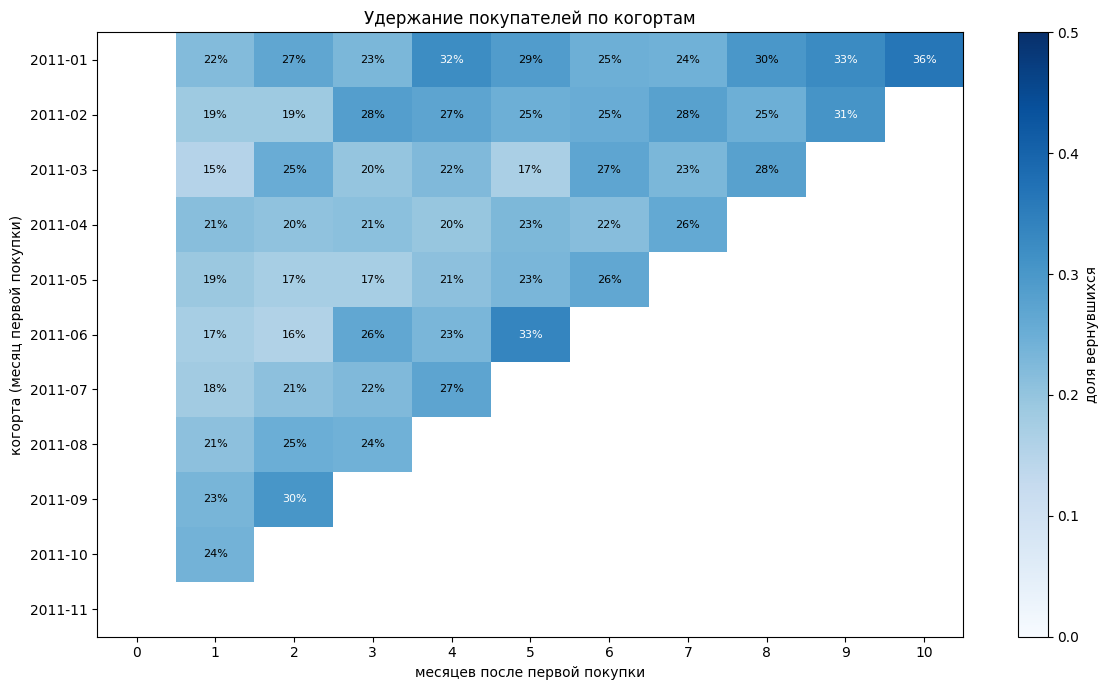

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

pivot = cohorts.pivot(index='cohort_month', columns='month_number', values='retention')
pivot.index = pd.to_datetime(pivot.index).strftime('%Y-%m')

fig, ax = plt.subplots(figsize=(12, 7))
plot_data = pivot.copy()
plot_data[0] = float('nan')
im = ax.imshow(plot_data.values, cmap='Blues', aspect='auto', vmin=0, vmax=0.5)

ax.set_xticks(range(len(pivot.columns)))
ax.set_xticklabels(pivot.columns)
ax.set_yticks(range(len(pivot.index)))
ax.set_yticklabels(pivot.index)
ax.set_xlabel('месяцев после первой покупки')
ax.set_ylabel('когорта (месяц первой покупки)')
ax.set_title('Удержание покупателей по когортам')

for i in range(pivot.shape[0]):
    for j in range(pivot.shape[1]):
        v = pivot.values[i, j]
        if pd.notna(v) and j > 0:
            ax.text(j, i, f'{v:.0%}', ha='center', va='center', fontsize=8,
                    color='white' if v > 0.3 else 'black')

fig.colorbar(im, ax=ax, label='доля вернувшихся')
plt.tight_layout()
plt.show()

Удержание на первый месяц около 20%. Доля вернувшихся не падает, а к концу года растет. Ну и есть сезонность, самый высокий у всех в ноябре: перед Рождеством оптовики закупают подарочные товары.
Рекомендации
стимулировать 2 покупку, так как кто купил 2 обычно остаются
важно заметить что были удалены 135 тысяч строк без id клиента, результат из-за них может быть смещен.
Удержание считается только по покупке без суммы и оптовик и тот кто купил немного считаются одинаково, а для бизнеса приносят разный доход
